# Notebook 02 — Historical Simulation VaR

Historical Simulation estimates portfolio risk using actual market data without making any assumptions about the underlying return distribution.

The portfolio's daily returns are sorted from worst to best, and Value at Risk (VaR) is calculated from the lower tail of the historical return distribution. Expected Shortfall (ES) is also computed to measure the average loss beyond the VaR threshold.

Because this approach relies entirely on historical observations, periods of market stress such as the COVID-19 crash are naturally reflected in the results.

## Outputs

- Historical VaR (95%, 99%)
- Expected Shortfall (95%, 99%)
- Diversification Benefit
- Risk visualizations

Portfolio Summary
count    2514.0000
mean        0.0005
std         0.0125
min        -0.1181
25%        -0.0050
50%         0.0006
75%         0.0066
max         0.1068
dtype: object

Historical VaR (95%)
  VaR        : 1.8059%  ($18,059)
  ES         : 2.9597%  ($29,597)
  ES / VaR   : 1.64x

Historical VaR (99%)
  VaR        : 3.4243%  ($34,243)
  ES         : 5.1457%  ($51,457)
  ES / VaR   : 1.50x

Diversification Benefit (95%): $6,317 per day


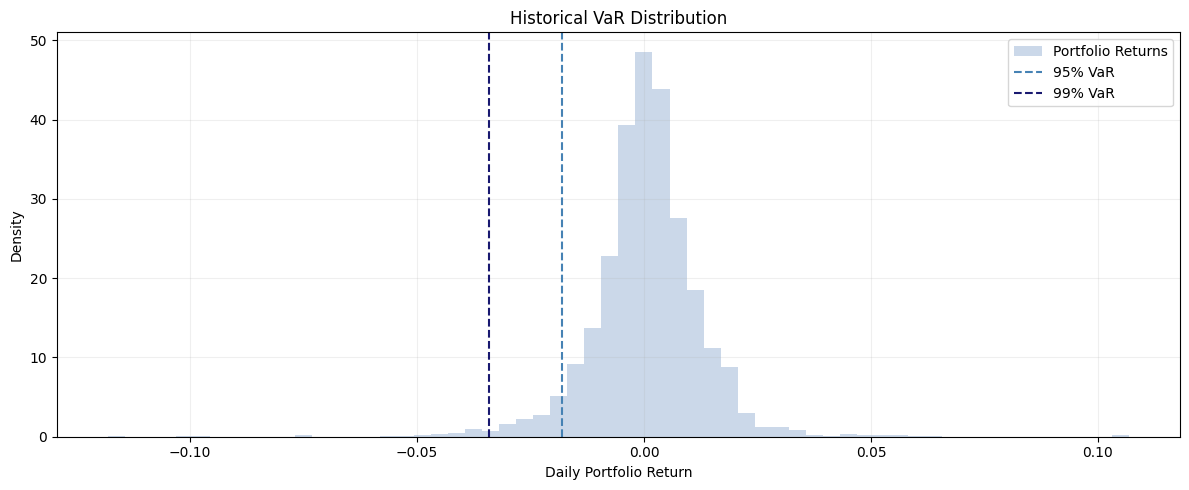

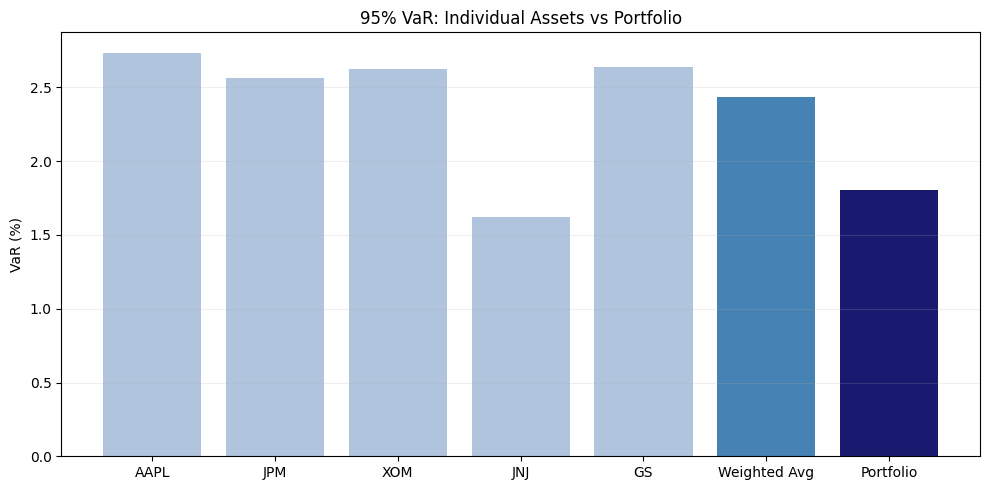

In [1]:
# Reference: Hull, Options, Futures and Other Derivatives

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration
TICKERS = ['AAPL', 'JPM', 'XOM', 'JNJ', 'GS']

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

confidence_levels = [0.95, 0.99]

portfolio_value = 1_000_000

# Load Data
log_returns = pd.read_csv('../data/log_returns.csv',index_col=0, parse_dates=True)

assert log_returns.isna().sum().sum() == 0

# Portfolio Returns

portfolio_returns = log_returns.dot(weights)

print("Portfolio Summary")
print(portfolio_returns.describe().apply(lambda x: f"{x:.4f}"))

# Historical VaR and Expected Shortfall 
results = {}

for cl in confidence_levels:

    tail = 1 - cl

    var_pct = -np.percentile(portfolio_returns, tail * 100)

    es_pct = -portfolio_returns[portfolio_returns <= -var_pct].mean()

    var_dollar = var_pct * portfolio_value
    es_dollar = es_pct * portfolio_value

    results[cl] = {
        'var_pct': var_pct,
        'es_pct': es_pct,
        'var_dollar': var_dollar,
        'es_dollar': es_dollar
    }

    print(f"\nHistorical VaR ({cl*100:.0f}%)")
    print(f"  VaR        : {var_pct*100:.4f}%  (${var_dollar:,.0f})")
    print(f"  ES         : {es_pct*100:.4f}%  (${es_dollar:,.0f})")
    print(f"  ES / VaR   : {es_pct/var_pct:.2f}x")

# Diversification Benefit

individual_vars = {}

for ticker in TICKERS:
    individual_vars[ticker] = -np.percentile(log_returns[ticker], 5)

weighted_avg_var = sum( weights[i] * individual_vars[ticker] for i, ticker in enumerate(TICKERS))

div_benefit = (weighted_avg_var - results[0.95]['var_pct']) * portfolio_value

print(f"\nDiversification Benefit (95%): ${div_benefit:,.0f} per day")

# Chart 1: Historical Return Distribution
fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(
    portfolio_returns,
    bins=60,
    density=True,
    color='lightsteelblue',
    alpha=0.65,
    label='Portfolio Returns')

ax.axvline(
    -results[0.95]['var_pct'],
    color='steelblue',
    linestyle='--',
    linewidth=1.5,
    label='95% VaR')

ax.axvline(
    -results[0.99]['var_pct'],
    color='midnightblue',
    linestyle='--',
    linewidth=1.5,
    label='99% VaR')

ax.set_title('Historical VaR Distribution')
ax.set_xlabel('Daily Portfolio Return')
ax.set_ylabel('Density')

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

os.makedirs('../reports', exist_ok=True)

plt.savefig('../reports/02_historical_var_distribution.png',dpi=150)

plt.show()

# Chart 2: Diversification Benefit 

fig, ax = plt.subplots(figsize=(10, 5))

labels = TICKERS + ['Weighted Avg', 'Portfolio']

values = []

for ticker in TICKERS:
    values.append(individual_vars[ticker] * 100)

values.append(weighted_avg_var * 100)
values.append(results[0.95]['var_pct'] * 100)

colors = (
    ['lightsteelblue'] * len(TICKERS)
    + ['steelblue']
    + ['midnightblue'])

ax.bar(
    labels,
    values,
    color=colors)

ax.set_title('95% VaR: Individual Assets vs Portfolio')
ax.set_ylabel('VaR (%)')

ax.grid(alpha=0.2, axis='y')

plt.tight_layout()

plt.savefig( '../reports/02_diversification_benefit.png', dpi=150)

plt.show()